# Predizione del vincitore di una partita di tennis con un Decision Tree (criterio Gini)

## Obiettivo

Il problema e' una **classificazione binaria**:

- classe `1`: vince il giocatore A;
- classe `0`: vince il giocatore B.

L'obiettivo e' addestrare un `DecisionTreeClassifier` di scikit-learn con
criterio Gini, confrontare le prestazioni con e senza le feature derivate
dalle quote di mercato, e verificare se il modello generalizza sulle
partite disputate dopo quelle usate per l'addestramento.

## Perche' un Decision Tree con criterio Gini?

Un singolo albero decisionale e' facilmente interpretabile: la struttura
dell'albero e le regole di split possono essere ispezionate direttamente,
a differenza di un ensemble come CatBoost. Il criterio Gini misura
l'impurita' di un nodo e guida la scelta dello split che la riduce di piu'.

Per contenere l'overfitting tipico di un albero singolo, gli iperparametri
(profondita' massima, dimensione minima delle foglie, dimensione minima di
split, cost-complexity pruning `ccp_alpha`) vengono selezionati tramite
grid search, con fold di cross-validation costruiti su **date uniche**
(non sull'indice di riga) cosi' le due osservazioni simmetriche generate da
ogni match restano sempre nello stesso fold.

## Configurazione

*Import e costanti (`HOLDOUT_FRACTION`, `CV_FOLDS`, criterio Gini, seed)
replicano `scripts/models/train_decision_tree.py`; le funzioni importate
(`chronological_holdout_split`, `load_feature_dataset`,
`make_date_based_folds`) sono definite in
`scripts/models/training_utils.py`.*

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "scripts" / "models"))

from training_utils import (  # noqa: E402
    chronological_holdout_split,
    load_feature_dataset,
    make_date_based_folds,
)

FEATURES_PATH = PROJECT_ROOT / "data/interim/tennis_matches_features.data"
METADATA_PATH = PROJECT_ROOT / "data/interim/tennis_matches_features_metadata.json"

HOLDOUT_FRACTION = 0.15
CV_FOLDS = 5
ODDS_FEATURES = {
    "has_any_market_odds",
    "winner_implied_prob_avg",
    "loser_implied_prob_avg",
    "implied_prob_diff_avg",
}

RANDOM_SEED = 42

## 1. Caricamento del dataset

*Usa `load_feature_dataset` da `scripts/models/training_utils.py` (righe
35-96), la stessa funzione richiamata da `train_decision_tree.py`.*

In [2]:
dataset_with_odds = load_feature_dataset(FEATURES_PATH, METADATA_PATH)
dataset_without_odds = load_feature_dataset(
    FEATURES_PATH, METADATA_PATH, excluded_features=ODDS_FEATURES
)

print("Righe:", len(dataset_with_odds.features))
print("Feature numeriche (con quote):", len(dataset_with_odds.numeric_features))
print("Feature categoriche (con quote):", len(dataset_with_odds.categorical_features))
print("Feature numeriche (senza quote):", len(dataset_without_odds.numeric_features))

preview = dataset_with_odds.features.copy()
preview["date"] = dataset_with_odds.dates
preview["player_a_win"] = dataset_with_odds.target
display(preview.head())

Righe: 56292
Feature numeriche (con quote): 64
Feature categoriche (con quote): 5
Feature numeriche (senza quote): 60


,source_year,atp,best_of,round_ordinal,winner_rank,loser_rank,rank_diff,winner_rank_missing,loser_rank_missing,winner_points,...,winner_bp_faced_per_sv_game_before,loser_bp_faced_per_sv_game_before,bp_faced_per_sv_game_diff,series,court,surface,tournament_bucket,location_bucket,date,player_a_win
0,2015,1,3.0,0.0,72.0,31.0,-41.0,0,0,691.0,...,0.649068,0.540598,0.108471,ATP250,Outdoor,Hard,Brisbane International,Brisbane,2015-01-05,0
1,2015,1,3.0,0.0,31.0,72.0,41.0,0,0,1195.0,...,0.540598,0.649068,-0.108471,ATP250,Outdoor,Hard,Brisbane International,Brisbane,2015-01-05,1
2,2015,1,3.0,0.0,21.0,125.0,104.0,0,0,1730.0,...,NaN,0.590551,NaN,ATP250,Outdoor,Hard,Brisbane International,Brisbane,2015-01-05,0
3,2015,1,3.0,0.0,125.0,21.0,-104.0,0,0,430.0,...,0.590551,NaN,NaN,ATP250,Outdoor,Hard,Brisbane International,Brisbane,2015-01-05,1
4,2015,1,3.0,0.0,25.0,149.0,124.0,0,0,1365.0,...,0.528654,0.545455,-0.016801,ATP250,Outdoor,Hard,Brisbane International,Brisbane,2015-01-05,0


Il dataset contiene due righe per ogni partita reale, una per ciascun
orientamento dei giocatori (`player_a_win` bilanciato). Sono usate solo
informazioni disponibili prima della partita: ranking, punti, forma
recente, scontri diretti, rendimento sulla superficie, statistiche
storiche dei giocatori e, quando disponibili, le probabilita' implicite di
mercato.

La versione "senza quote" esclude `has_any_market_odds`,
`winner_implied_prob_avg`, `loser_implied_prob_avg` e
`implied_prob_diff_avg`, per isolare il contributo delle feature costruite
nella fase di feature engineering rispetto a quello delle quote dei
bookmaker.

## 2. Split cronologico: fold per la grid search e holdout finale

Una divisione casuale non e' appropriata: potrebbe addestrare il modello
su partite future e valutarlo su partite precedenti. Il 15% piu' recente
delle date uniche e' quindi riservato come **holdout finale**, mai
utilizzato durante il tuning. I fold di cross-validation per la grid
search sono costruiti sulle date del solo training set, cosi' le due
orientazioni della stessa partita (stessa data) restano sempre nello
stesso fold.

*`chronological_holdout_split` e `make_date_based_folds` sono definite in
`scripts/models/training_utils.py` (righe 131+ e 99+), identiche a quelle
usate da `train_decision_tree.py`.*

In [3]:
train_idx, holdout_idx = chronological_holdout_split(
    dataset_with_odds.dates, HOLDOUT_FRACTION
)

X_train, y_train = dataset_with_odds.features.iloc[train_idx], dataset_with_odds.target.iloc[train_idx]
X_holdout, y_holdout = dataset_with_odds.features.iloc[holdout_idx], dataset_with_odds.target.iloc[holdout_idx]
dates_train = dataset_with_odds.dates.iloc[train_idx].reset_index(drop=True)

X_train_no_odds = dataset_without_odds.features.iloc[train_idx]
X_holdout_no_odds = dataset_without_odds.features.iloc[holdout_idx]

cv_folds = make_date_based_folds(dates_train, CV_FOLDS)

print(f"Training: {len(X_train):,} righe")
print(f"Holdout finale: {len(X_holdout):,} righe (ultimo {HOLDOUT_FRACTION:.0%} delle date)")
print(f"Fold di cross-validation: {len(cv_folds)}")

Training: 48,134 righe
Holdout finale: 8,158 righe (ultimo 15% delle date)
Fold di cross-validation: 5


## 3. Baseline ingenua

Il classificatore va confrontato con una baseline semplice, che predice
sempre la classe maggioritaria. Poiche' il dataset simmetrico e'
bilanciato, l'accuratezza attesa della baseline e' circa il 50%.

*Blocco presente solo nel notebook: `train_decision_tree.py` (lo script a
riga di comando) non calcola questa baseline.*

In [4]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_holdout, baseline.predict(X_holdout))

print(f"Accuratezza della baseline ingenua: {baseline_accuracy:.4f}")

Accuratezza della baseline ingenua: 0.5000


## 4. Pipeline e grid search — modello con le feature di mercato

*`build_pipeline` e `param_grid` replicano esattamente
`scripts/models/train_decision_tree.py` righe 165-201 (stesso
`criterion="gini"`, `random_state=42`, stessa griglia di iperparametri).*

In [5]:
def build_pipeline(numeric_features, categorical_features):
    preprocess = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), list(numeric_features)),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                list(categorical_features),
            ),
        ],
        remainder="drop",
    )
    return Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", DecisionTreeClassifier(criterion="gini", random_state=RANDOM_SEED)),
        ]
    )


param_grid = {
    "model__max_depth": [4, 6, 8, 10, 12, None],
    "model__min_samples_leaf": [1, 5, 20, 50],
    "model__min_samples_split": [2, 20, 50],
    "model__ccp_alpha": [0.0, 0.0005, 0.001, 0.005],
}

pipeline_with_odds = build_pipeline(
    dataset_with_odds.numeric_features, dataset_with_odds.categorical_features
)

search_with_odds = GridSearchCV(
    pipeline_with_odds,
    param_grid=param_grid,
    cv=cv_folds,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
)
search_with_odds.fit(X_train, y_train)

print("Migliori parametri (con quote):", search_with_odds.best_params_)
print(f"Miglior accuratezza CV (con quote): {search_with_odds.best_score_:.4f}")

Migliori parametri (con quote): {'model__ccp_alpha': 0.001, 'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Miglior accuratezza CV (con quote): 0.6822


## 5. Pipeline e grid search — modello senza le feature di mercato

*Stessa `build_pipeline`/`param_grid` della sezione 4, applicata al
dataset senza le feature di quote. Nello script a riga di comando questo
corrisponde a una seconda esecuzione di `train_decision_tree.py` con
`--exclude-features`; qui e' fatto nella stessa run per il confronto
diretto.*

In [6]:
pipeline_no_odds = build_pipeline(
    dataset_without_odds.numeric_features, dataset_without_odds.categorical_features
)

search_no_odds = GridSearchCV(
    pipeline_no_odds,
    param_grid=param_grid,
    cv=cv_folds,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
)
search_no_odds.fit(X_train_no_odds, y_train)

print("Migliori parametri (senza quote):", search_no_odds.best_params_)
print(f"Miglior accuratezza CV (senza quote): {search_no_odds.best_score_:.4f}")

Migliori parametri (senza quote): {'model__ccp_alpha': 0.0, 'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Miglior accuratezza CV (senza quote): 0.6390


## 6. Valutazione sull'holdout: con quote vs senza quote

*L'accuratezza su holdout replica `train_decision_tree.py` righe 227-231;
la tabella affiancata con/senza quote e' pero' un'aggregazione fatta solo
nel notebook (nello script servirebbero due esecuzioni separate, come in
`data/interim/decision_tree_metrics.json` e
`data/interim/decision_tree_no_odds.json`).*

In [7]:
best_with_odds = search_with_odds.best_estimator_
best_no_odds = search_no_odds.best_estimator_

holdout_pred_with_odds = best_with_odds.predict(X_holdout)
holdout_pred_no_odds = best_no_odds.predict(X_holdout_no_odds)

comparison = pd.DataFrame(
    {
        "Con quote": {
            "Accuratezza CV": search_with_odds.best_score_,
            "Accuratezza holdout": accuracy_score(y_holdout, holdout_pred_with_odds),
        },
        "Senza quote": {
            "Accuratezza CV": search_no_odds.best_score_,
            "Accuratezza holdout": accuracy_score(y_holdout, holdout_pred_no_odds),
        },
    }
)
display(comparison)

,Con quote,Senza quote
Accuratezza CV,0.682181,0.638990
Accuratezza holdout,0.686443,0.649179


### Matrice di confusione (modello con quote)

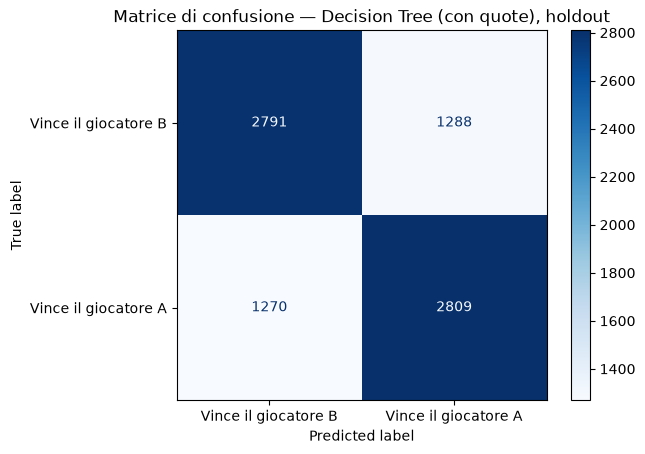

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    holdout_pred_with_odds,
    display_labels=["Vince il giocatore B", "Vince il giocatore A"],
    cmap="Blues",
)
plt.title("Matrice di confusione — Decision Tree (con quote), holdout")
plt.grid(False)
plt.show()

### Precisione, richiamo e F1-score (modello con quote)

In [9]:
print(
    classification_report(
        y_holdout,
        holdout_pred_with_odds,
        target_names=["Vince il giocatore B", "Vince il giocatore A"],
        digits=4,
    )
)

                      precision    recall  f1-score   support

Vince il giocatore B     0.6873    0.6842    0.6857      4079
Vince il giocatore A     0.6856    0.6886    0.6871      4079

            accuracy                         0.6864      8158
           macro avg     0.6864    0.6864    0.6864      8158
        weighted avg     0.6864    0.6864    0.6864      8158



## 7. Importanza delle feature

L'importanza delle feature indica quanto ciascuna variabile contribuisce
a ridurre l'impurita' Gini lungo l'albero. Aiuta a interpretare il
modello, ma non dimostra un rapporto causale.

*Logica equivalente a `train_decision_tree.py` righe 243-251 (il notebook
usa `feature_importances_` con `pandas.Series` invece di `sorted()` su una
lista, stesso risultato).*

,importance
num__implied_prob_diff_avg,1.0
cat__tournament_bucket_US Open,0.0
cat__location_bucket_'s-Hertogenbosch,0.0
cat__tournament_bucket_other,0.0
cat__tournament_bucket_Winston-Salem Open at Wake Forest University,0.0
cat__tournament_bucket_Wimbledon,0.0
cat__tournament_bucket_Western & Southern Financial Group Masters,0.0
cat__tournament_bucket_Vienna Open,0.0
cat__tournament_bucket_U.S. Men's Clay Court Championships,0.0
cat__tournament_bucket_St. Petersburg Open,0.0


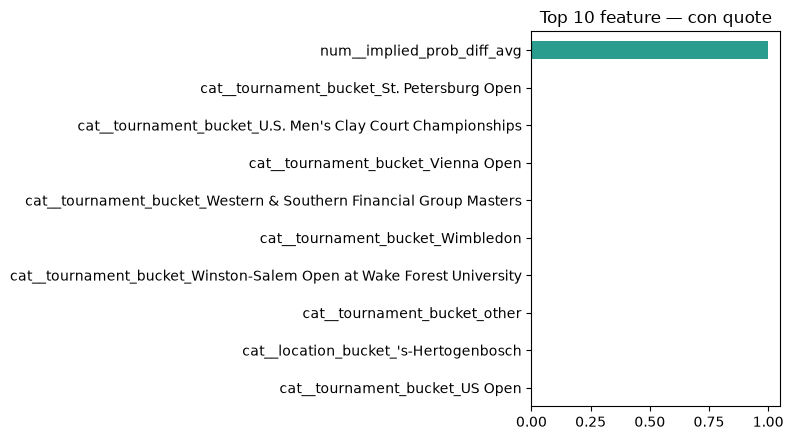

In [10]:
def top_feature_importances(fitted_pipeline, top_n=10):
    preprocess = fitted_pipeline.named_steps["preprocess"]
    tree = fitted_pipeline.named_steps["model"]
    feature_names = preprocess.get_feature_names_out()
    importances = pd.Series(tree.feature_importances_, index=feature_names, name="importance")
    return importances.sort_values(ascending=False).head(top_n)


importances_with_odds = top_feature_importances(best_with_odds)
display(importances_with_odds.to_frame())

importances_with_odds.sort_values().plot(
    kind="barh", figsize=(8, 4.5), color="#2a9d8f", title="Top 10 feature — con quote"
)
plt.tight_layout()
plt.show()

### Importanza delle feature — modello senza quote

,importance
num__rank_diff,0.648828
num__points_diff,0.226171
num__surface_win_rate_diff,0.097798
num__loser_matches_before,0.006955
num__winner_matches_before,0.006955
num__loser_bp_saved_rate_before,0.006731
num__winner_bp_saved_rate_before,0.006563
cat__tournament_bucket_Western & Southern Financial Group Masters,0.000000
cat__tournament_bucket_Wimbledon,0.000000
cat__tournament_bucket_Winston-Salem Open at Wake Forest University,0.000000


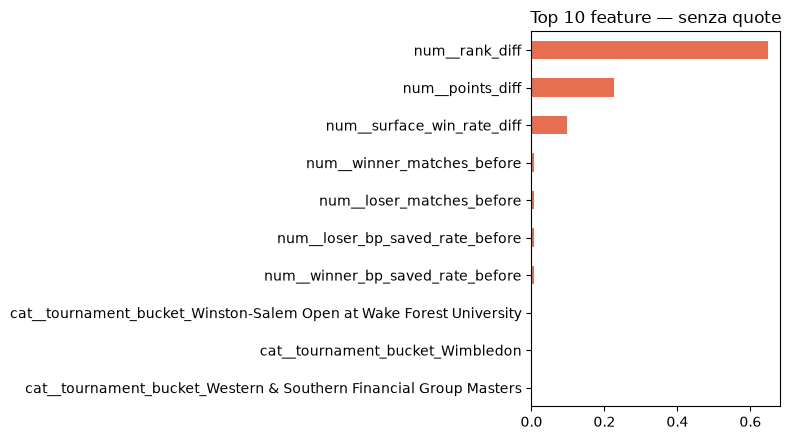

In [11]:
importances_no_odds = top_feature_importances(best_no_odds)
display(importances_no_odds.to_frame())

importances_no_odds.sort_values().plot(
    kind="barh", figsize=(8, 4.5), color="#e76f51", title="Top 10 feature — senza quote"
)
plt.tight_layout()
plt.show()

## 8. Struttura dell'albero (primi livelli, modello con quote)

*`export_text`/`plot_tree` replicano `train_decision_tree.py` righe
258-278.*

Profondita' albero: 3
Numero di foglie: 6

|--- num__implied_prob_diff_avg <= -0.00
|   |--- num__implied_prob_diff_avg <= -0.33
|   |   |--- num__implied_prob_diff_avg <= -0.56
|   |   |   |--- class: 0
|   |   |--- num__implied_prob_diff_avg >  -0.56
|   |   |   |--- class: 0
|   |--- num__implied_prob_diff_avg >  -0.33
|   |   |--- class: 0
|--- num__implied_prob_diff_avg >  -0.00
|   |--- num__implied_prob_diff_avg <= 0.33
|   |   |--- class: 1
|   |--- num__implied_prob_diff_avg >  0.33
|   |   |--- num__implied_prob_diff_avg <= 0.56
|   |   |   |--- class: 1
|   |   |--- num__implied_prob_diff_avg >  0.56
|   |   |   |--- class: 1



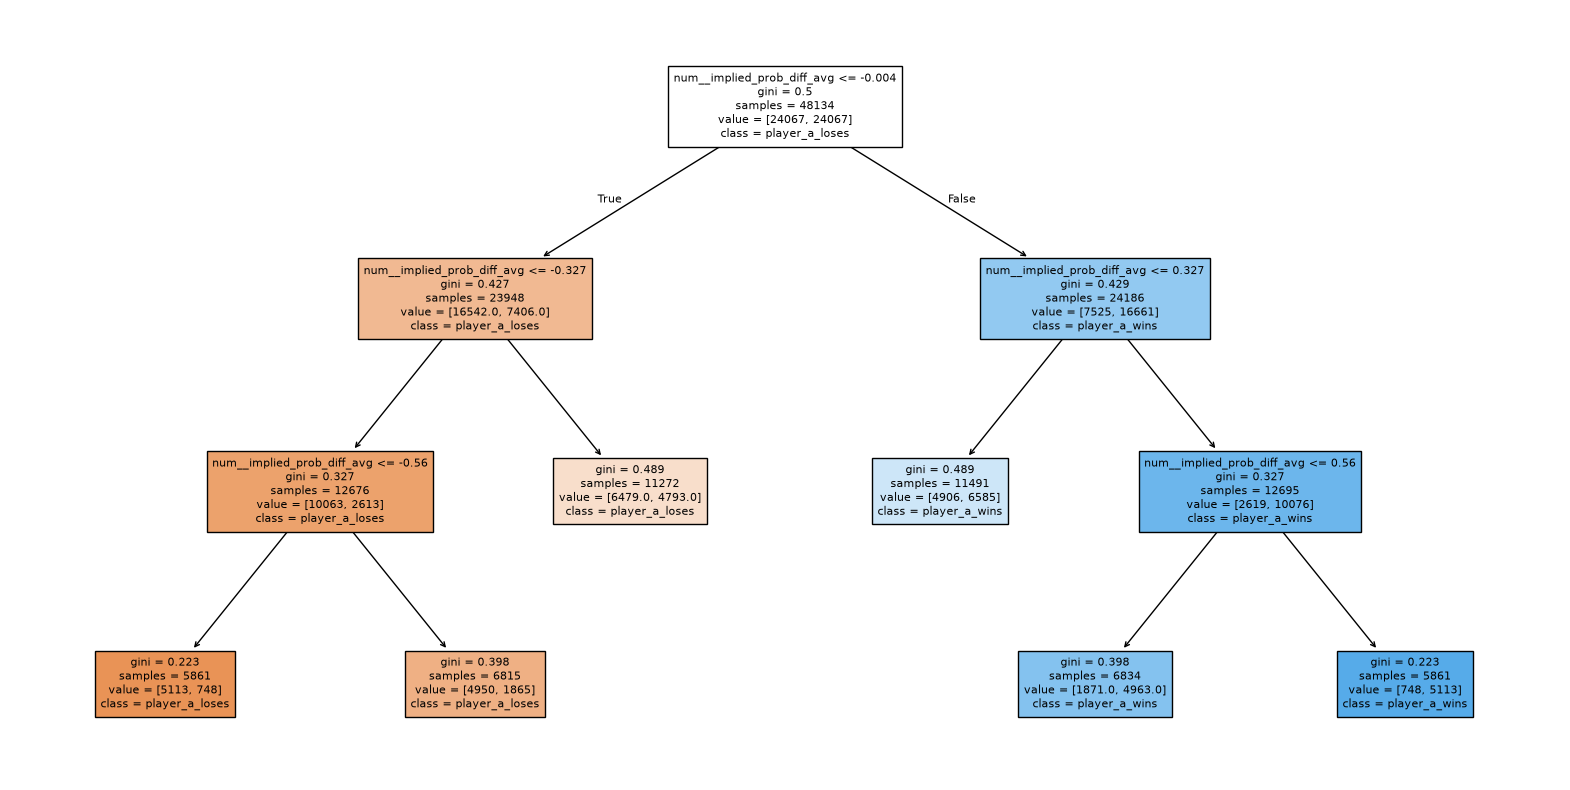

In [12]:
fitted_preprocess = best_with_odds.named_steps["preprocess"]
fitted_tree = best_with_odds.named_steps["model"]
feature_names = fitted_preprocess.get_feature_names_out().tolist()

print(f"Profondita' albero: {fitted_tree.get_depth()}")
print(f"Numero di foglie: {fitted_tree.get_n_leaves()}")
print()
print(export_text(fitted_tree, feature_names=feature_names, max_depth=3))

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=["player_a_loses", "player_a_wins"],
    filled=True,
    max_depth=3,
    fontsize=8,
    ax=ax,
)
plt.show()

## 9. Analisi delle partite piu' facili e piu' difficili (modello con quote)

*Sezione presente solo nel notebook, non in `train_decision_tree.py`.
**Nota**: la cella seguente ricostruisce un id di partita sintetico
(data + torneo + round + coppia di giocatori) perche' il dataset attuale
non contiene una colonna `match_id_internal`; questa riga di codice non
era nella versione originale ed e' stata aggiunta per far funzionare la
diagnostica con l'attuale `tennis_matches_features.data`.*

Le righe sono abbinate tramite un id di partita ricostruito da data,
torneo, round e coppia di giocatori (il dataset non include un id di
partita esplicito), cosi' ogni partita reale viene contata una sola volta
per questa diagnostica; le metriche principali sopra restano quelle
calcolate per riga. La probabilita' assegnata al vincitore reale e'
mediata tra i due orientamenti. Le previsioni piu' corrette assegnano la
probabilita' maggiore al vincitore reale; quelle piu' errate la minore.

In [13]:
holdout_probability = best_with_odds.predict_proba(X_holdout)[:, 1]

raw = pd.read_csv(FEATURES_PATH)
raw["date"] = pd.to_datetime(raw["date"], errors="raise")
holdout_raw = raw.iloc[holdout_idx].copy()

# Il dataset non include un id di partita esplicito: le due righe di ogni
# partita reale (un orientamento per riga) condividono data, torneo, round
# e la stessa coppia di giocatori, quindi quella combinazione basta a
# ricostruire un id univoco da usare per il raggruppamento.
holdout_raw["match_id_internal"] = list(
    zip(
        holdout_raw["date"],
        holdout_raw["tournament"],
        holdout_raw["round"],
        holdout_raw[["winner_name", "loser_name"]].apply(
            lambda row: tuple(sorted(row)), axis=1
        ),
    )
)

holdout_raw["actual_winner_probability"] = np.where(
    y_holdout.eq(1).to_numpy(), holdout_probability, 1 - holdout_probability
)
holdout_raw["actual_winner_probability"] = holdout_raw.groupby("match_id_internal")[
    "actual_winner_probability"
].transform("mean")

match_diagnostics = (
    holdout_raw.loc[holdout_raw["player_a_win"].eq(1)]
    .set_index("match_id_internal")
    .assign(correct=lambda df: df["actual_winner_probability"].ge(0.5))
)

instance_columns = [
    "date",
    "winner_name",
    "loser_name",
    "surface",
    "round",
    "winner_rank",
    "loser_rank",
    "actual_winner_probability",
]
instance_columns = [c for c in instance_columns if c in match_diagnostics.columns]

print("Partite nell'holdout:", len(match_diagnostics))
print(f"Accuratezza per partita: {match_diagnostics['correct'].mean():.4f}")

Partite nell'holdout: 4079
Accuratezza per partita: 0.6886


### Previsioni corrette con maggiore confidenza

In [14]:
display(match_diagnostics.nlargest(10, "actual_winner_probability")[instance_columns])

,date,winner_name,loser_name,surface,round,winner_rank,loser_rank,actual_winner_probability
match_id_internal,,,,,,,,
"(2024-11-10 00:00:00, Masters Cup, Round Robin, (De Minaur A., Sinner J.))",2024-11-10,Sinner J.,De Minaur A.,Hard,Round Robin,1.0,9.0,0.872377
"(2024-11-12 00:00:00, Masters Cup, Round Robin, (Fritz T., Sinner J.))",2024-11-12,Sinner J.,Fritz T.,Hard,Round Robin,1.0,5.0,0.872377
"(2024-11-13 00:00:00, Masters Cup, Round Robin, (Ruud C., Zverev A.))",2024-11-13,Zverev A.,Ruud C.,Hard,Round Robin,2.0,7.0,0.872377
"(2024-11-14 00:00:00, Masters Cup, Round Robin, (Medvedev D., Sinner J.))",2024-11-14,Sinner J.,Medvedev D.,Hard,Round Robin,1.0,4.0,0.872377
"(2024-11-16 00:00:00, Masters Cup, Semifinals, (Ruud C., Sinner J.))",2024-11-16,Sinner J.,Ruud C.,Hard,Semifinals,1.0,7.0,0.872377
"(2024-11-17 00:00:00, Masters Cup, Final, (Fritz T., Sinner J.))",2024-11-17,Sinner J.,Fritz T.,Hard,Final,1.0,5.0,0.872377
"(2024-12-30 00:00:00, Brisbane International, 1st Round, (Dimitrov G., Hanfmann Y.))",2024-12-30,Dimitrov G.,Hanfmann Y.,Hard,1st Round,10.0,96.0,0.872377
"(2024-12-31 00:00:00, Brisbane International, 1st Round, (Djokovic N., Hijikata R.))",2024-12-31,Djokovic N.,Hijikata R.,Hard,1st Round,7.0,73.0,0.872377
"(2025-01-01 00:00:00, Brisbane International, 2nd Round, (Dimitrov G., Vukic A.))",2025-01-01,Dimitrov G.,Vukic A.,Hard,2nd Round,10.0,68.0,0.872377


### Previsioni errate con maggiore confidenza

In [15]:
display(match_diagnostics.nsmallest(10, "actual_winner_probability")[instance_columns])

,date,winner_name,loser_name,surface,round,winner_rank,loser_rank,actual_winner_probability
match_id_internal,,,,,,,,
"(2024-11-11 00:00:00, Masters Cup, Round Robin, (Alcaraz C., Ruud C.))",2024-11-11,Ruud C.,Alcaraz C.,Hard,Round Robin,7.0,3.0,0.127623
"(2025-01-03 00:00:00, Brisbane International, Quarterfinals, (Djokovic N., Opelka R.))",2025-01-03,Opelka R.,Djokovic N.,Hard,Quarterfinals,293.0,7.0,0.127623
"(2025-01-06 00:00:00, ASB Classic, 1st Round, (Diaz Acosta F., Norrie C.))",2025-01-06,Diaz Acosta F.,Norrie C.,Hard,1st Round,78.0,48.0,0.127623
"(2025-01-07 00:00:00, Adelaide International, 1st Round, (Guinard M., Safiullin R.))",2025-01-07,Guinard M.,Safiullin R.,Hard,1st Round,261.0,62.0,0.127623
"(2025-01-14 00:00:00, Australian Open, 1st Round, (Moutet C., Popyrin A.))",2025-01-14,Moutet C.,Popyrin A.,Hard,1st Round,69.0,24.0,0.127623
"(2025-01-16 00:00:00, Australian Open, 2nd Round, (Fonseca J., Sonego L.))",2025-01-16,Sonego L.,Fonseca J.,Hard,2nd Round,55.0,112.0,0.127623
"(2025-01-16 00:00:00, Australian Open, 2nd Round, (Medvedev D., Tien L.))",2025-01-16,Tien L.,Medvedev D.,Hard,2nd Round,121.0,5.0,0.127623
"(2025-01-18 00:00:00, Australian Open, 3rd Round, (Fritz T., Monfils G.))",2025-01-18,Monfils G.,Fritz T.,Hard,3rd Round,41.0,4.0,0.127623
"(2025-02-05 00:00:00, ABN AMRO World Tennis Tournament, 1st Round, (Altmaier D., Kovacevic A.))",2025-02-05,Altmaier D.,Kovacevic A.,Hard,1st Round,93.0,75.0,0.127623


## Conclusioni

- La baseline ingenua ottiene circa il 50% di accuratezza, come atteso su
  un target bilanciato.
- Il confronto tra il modello con e senza le feature di mercato mostra
  quanto segnale predittivo autonomo portino ranking, punti e forma sulla
  superficie rispetto a quanto gia' incorporato nelle quote dei bookmaker.
- L'importanza delle feature e la struttura dell'albero permettono di
  verificare se il modello con le quote si riduce a un'unica soglia sulla
  probabilita' implicita, o se altre variabili contribuiscono in modo
  rilevante.
- L'analisi delle partite piu' difficili aiuta a capire se gli errori sono
  concentrati sui risultati a sorpresa (favorito sconfitto), coerentemente
  con quanto osservato per CatBoost.

Questo e' un rerun su un holdout esistente, non un nuovo test
indipendente: l'eventuale ulteriore tuning di feature o iperparametri va
fatto solo sui fold di cross-validation del training, non su questo
risultato.